In [112]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [113]:
df = pd.read_csv("/content/Bank Marketing.csv")

In [114]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [116]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [117]:
print("Shape of the dataset:", df.shape)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape of the dataset: (41188, 21)
Number of rows: 41188
Number of columns: 21


In [118]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()



print("Numerical features:")
print(numerical_columns)

print("\nCategorical features:")
print(categorical_columns)

Numerical features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


In [119]:
print("Target variable: y")

print(df["y"].value_counts())

Target variable: y
y
no     36548
yes     4640
Name: count, dtype: int64


In [120]:
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [121]:
df[categorical_columns].describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [122]:
df[numerical_columns].var()

,0
age,108.602451
duration,67225.728877
campaign,7.672975
pdays,34935.687284
previous,0.244927
emp.var.rate,2.467915
cons.price.idx,0.335056
cons.conf.idx,21.420215
euribor3m,3.008308
nr.employed,5220.283250


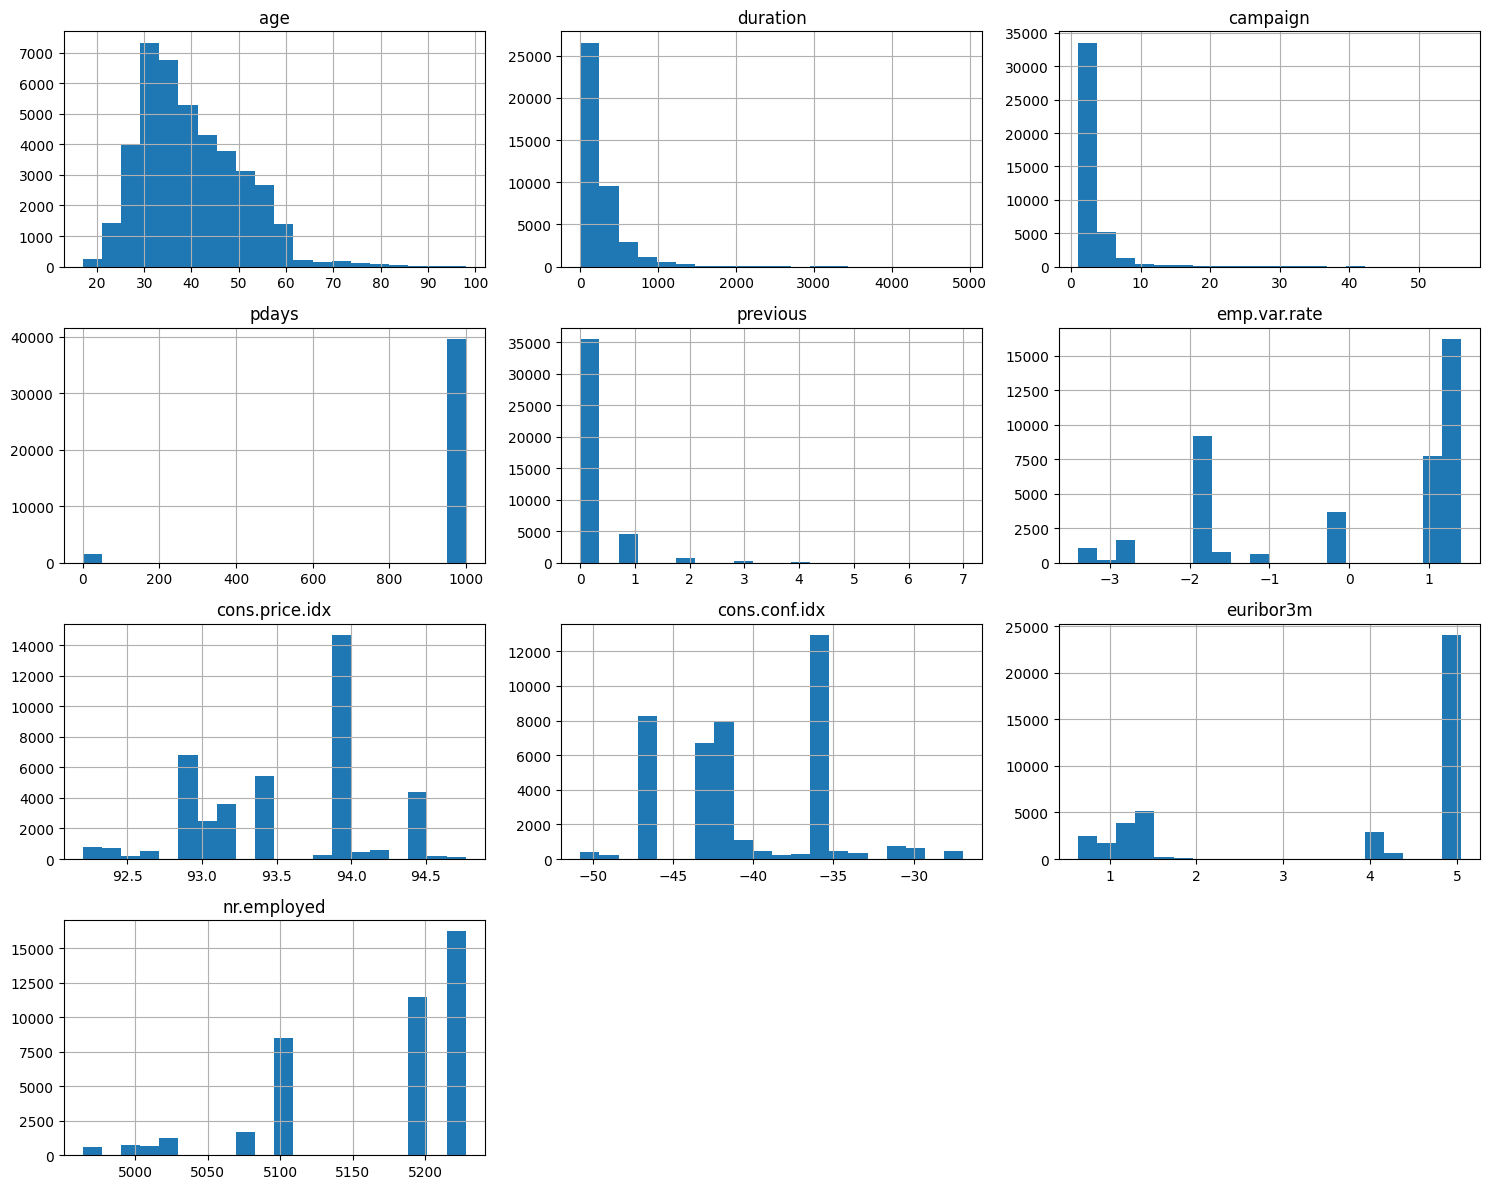

In [123]:
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20
)

plt.tight_layout()
plt.show()

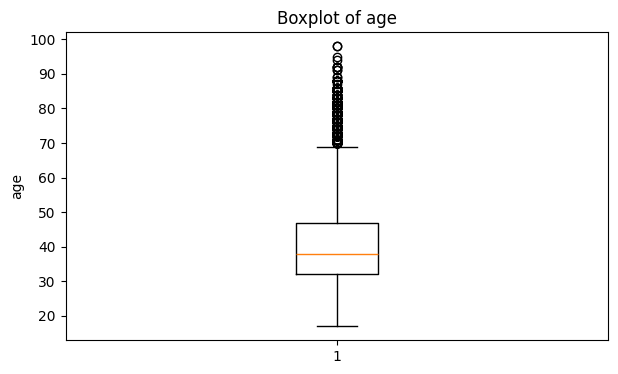

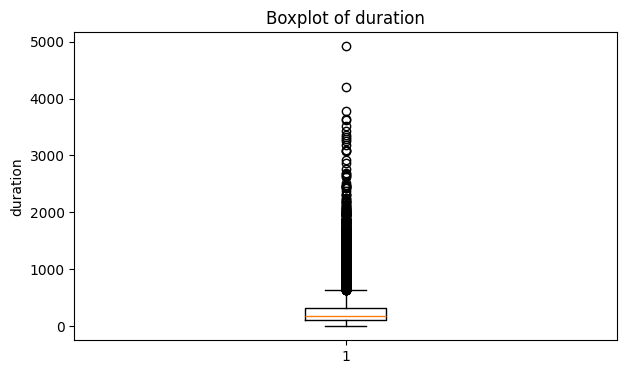

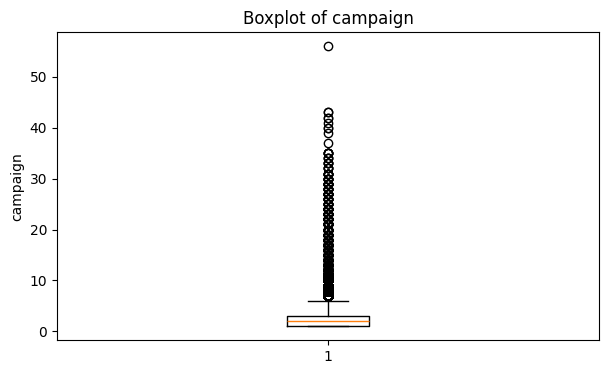

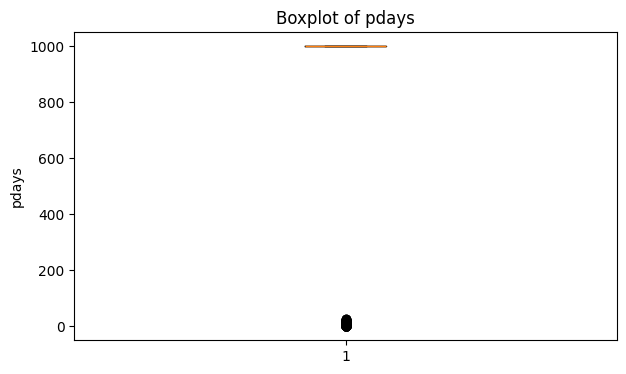

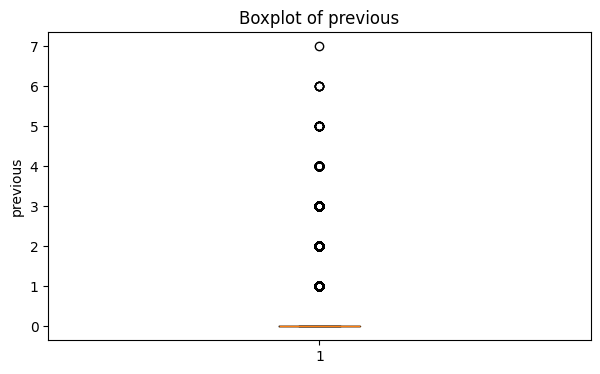

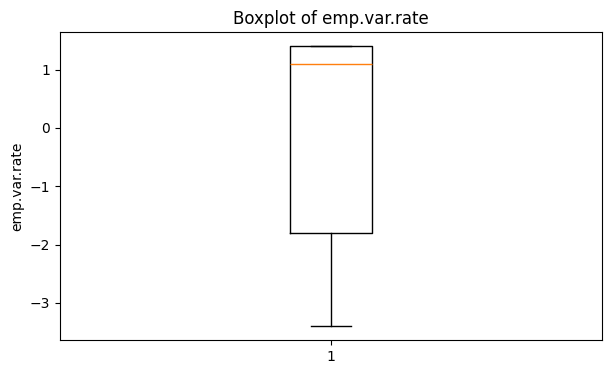

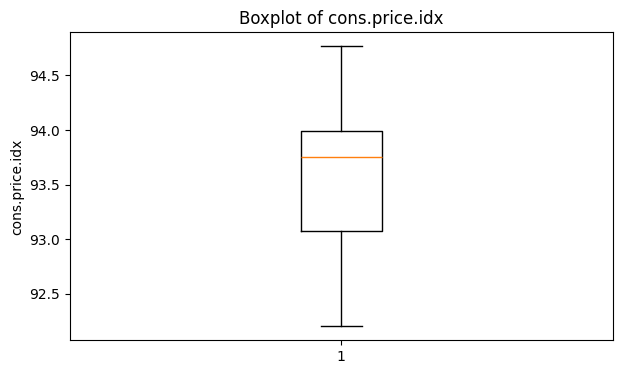

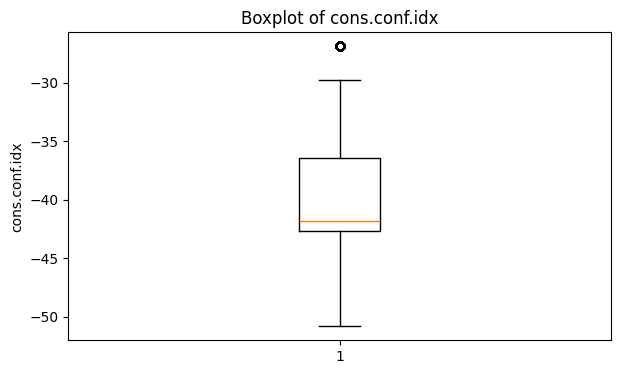

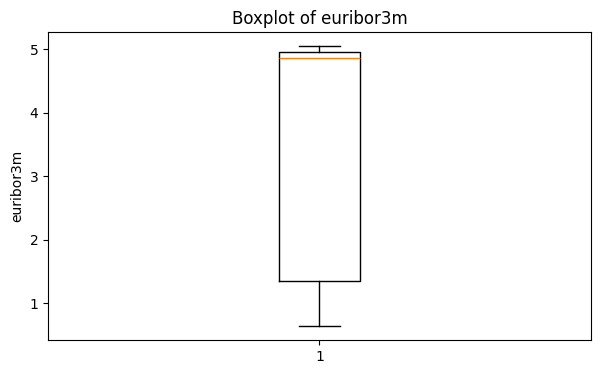

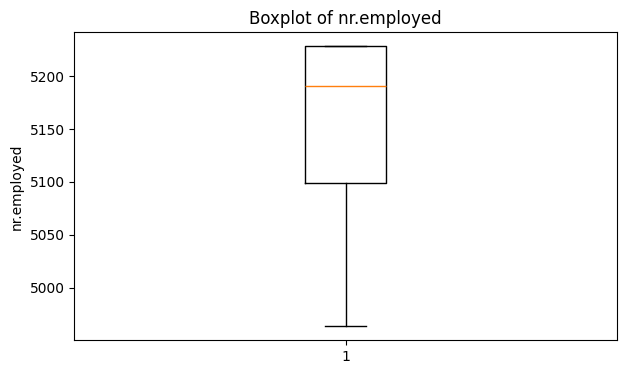

In [124]:
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    plt.boxplot(df[column])

    plt.title("Boxplot of " + column)
    plt.ylabel(column)

    plt.show()

In [125]:
unique_values = df.nunique()

print(unique_values)

age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous             8
poutcome             3
emp.var.rate        10
cons.price.idx      26
cons.conf.idx       26
euribor3m          316
nr.employed         11
y                    2
dtype: int64


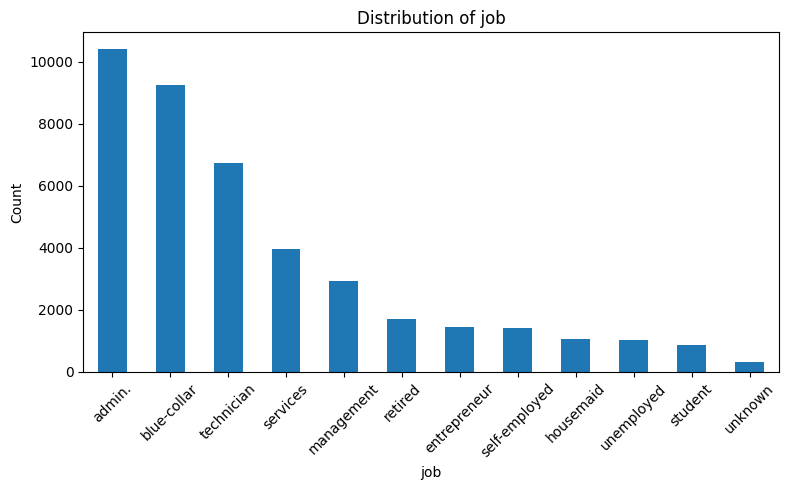

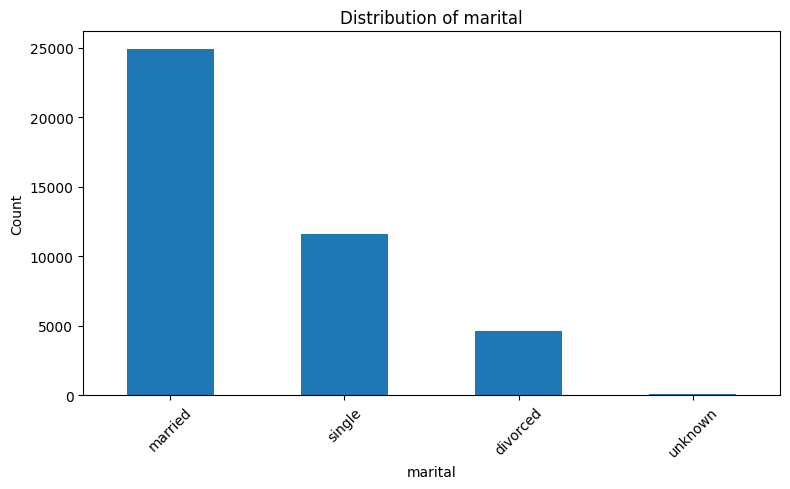

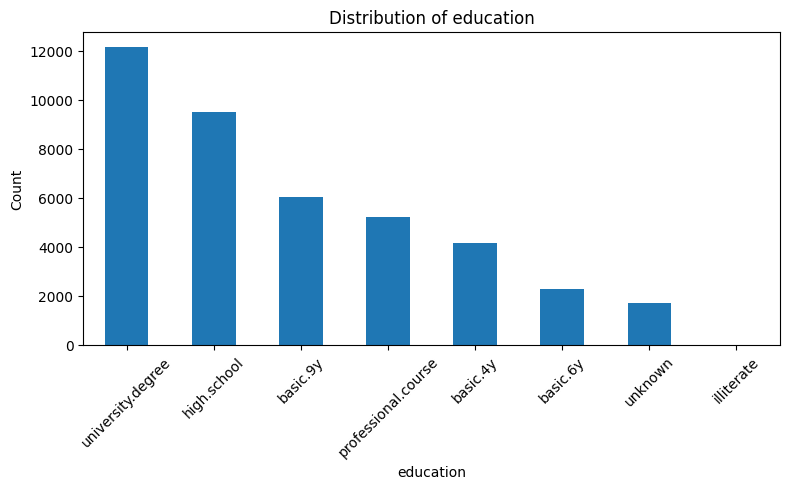

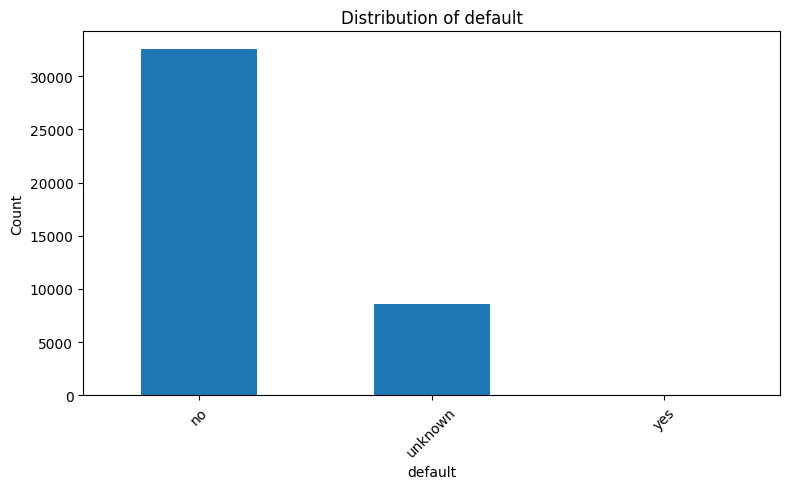

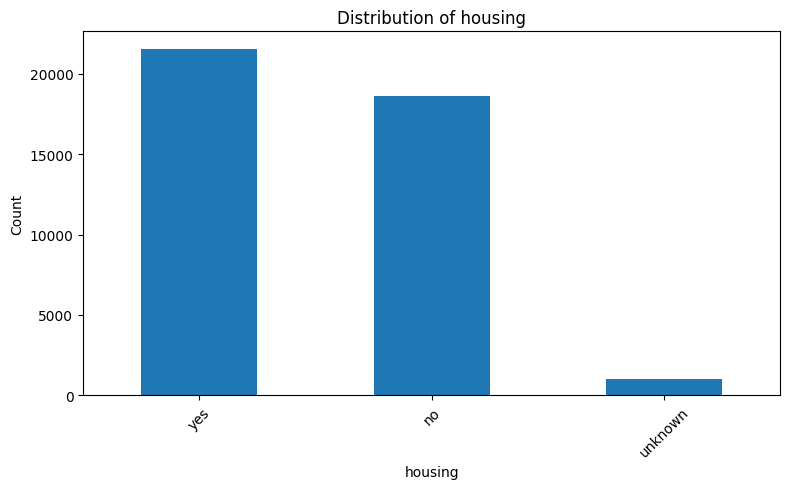

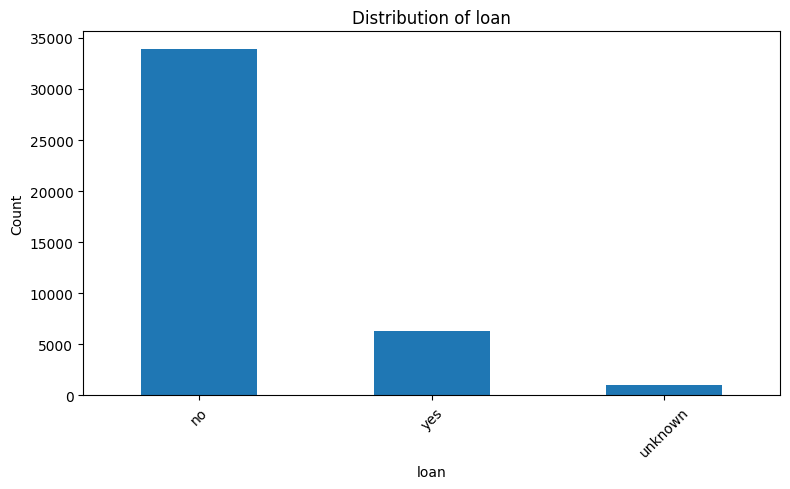

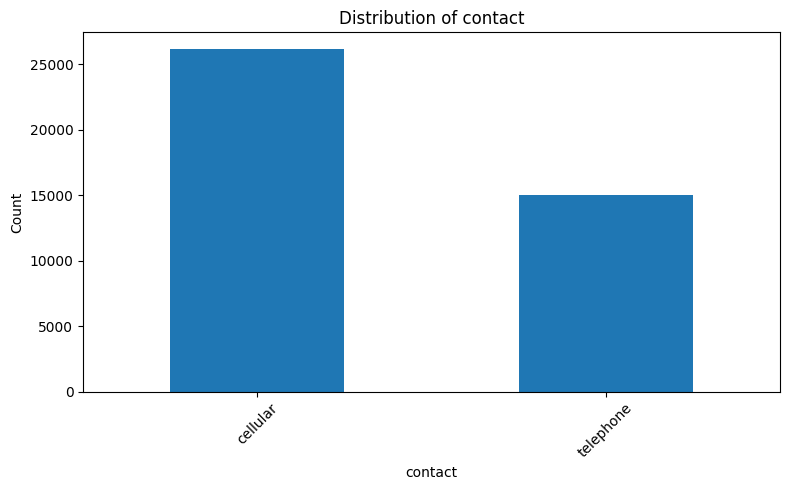

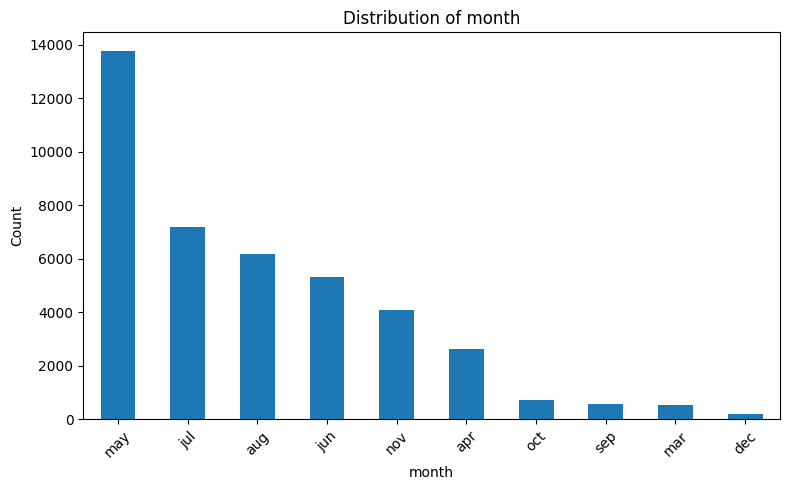

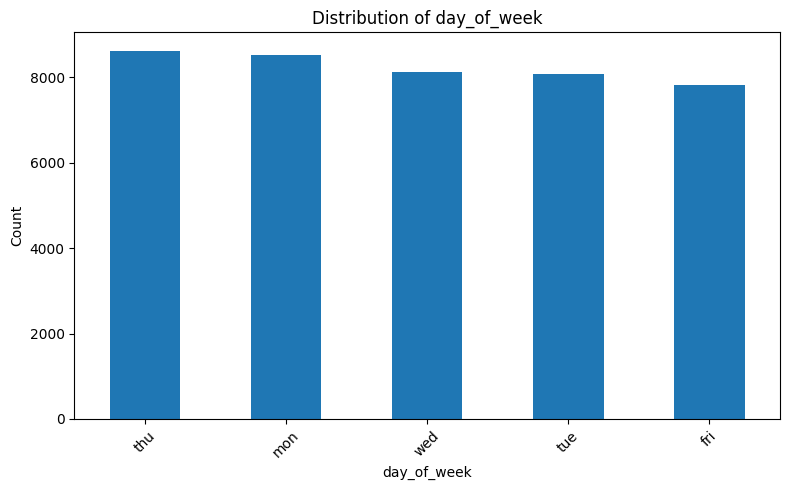

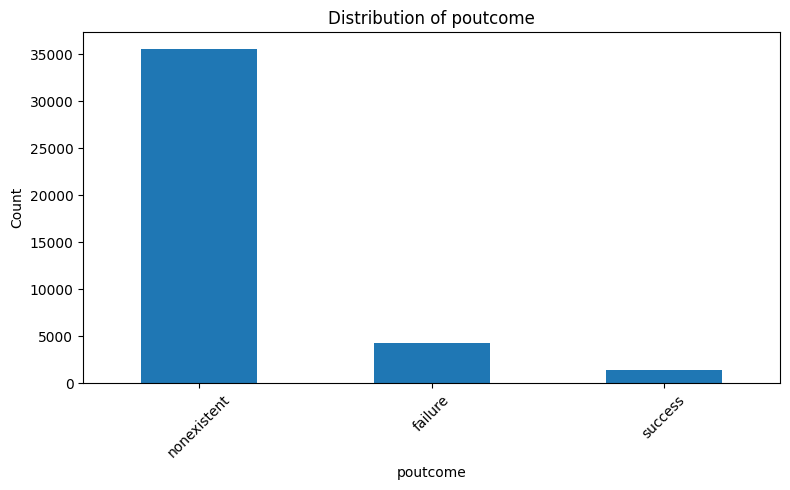

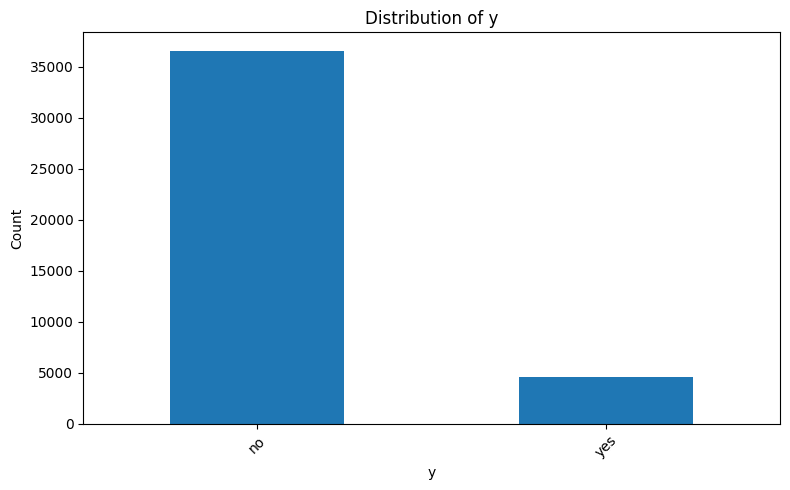

In [126]:
for column in categorical_columns:

    plt.figure(figsize=(8, 5))

    df[column].value_counts().plot(kind="bar")

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [127]:
for column in categorical_columns:

    print("\nColumn:", column)
    print(df[column].unique())


Column: job
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

Column: marital
['married' 'single' 'divorced' 'unknown']

Column: education
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

Column: default
['no' 'unknown' 'yes']

Column: housing
['no' 'yes' 'unknown']

Column: loan
['no' 'yes' 'unknown']

Column: contact
['telephone' 'cellular']

Column: month
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']

Column: day_of_week
['mon' 'tue' 'wed' 'thu' 'fri']

Column: poutcome
['nonexistent' 'failure' 'success']

Column: y
['no' 'yes']


In [128]:
missing_values = df.isnull().sum()

print(missing_values)

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [129]:
df.duplicated().sum()

np.int64(12)

In [130]:
df = df.drop_duplicates()

In [131]:
df.duplicated().sum()

np.int64(0)

In [132]:
unknown_summary = []

for column in df.columns:

    count = (df[column] == "unknown").sum()

    if count > 0:

        percentage = (count / len(df)) * 100

        unknown_summary.append([
            column,
            count,
            percentage
        ])

unknown_df = pd.DataFrame(
    unknown_summary,
    columns=["Feature", "Unknown Count", "Percentage"]
)

unknown_df

,Feature,Unknown Count,Percentage
0,job,330,0.801438
1,marital,80,0.194288
2,education,1730,4.201477
3,default,8596,20.876239
4,housing,990,2.404313
5,loan,990,2.404313


In [133]:
df["y"].value_counts()

,count
y,
no,36537
yes,4639


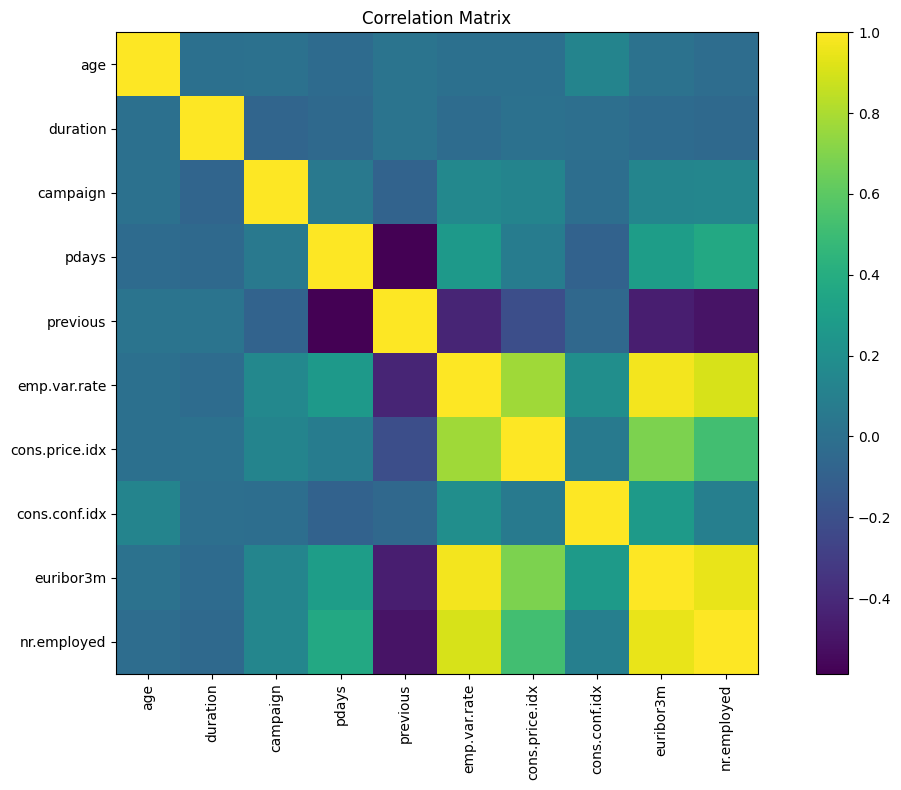

In [134]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()

In [135]:
df = df.replace("unknown", np.nan)

In [136]:
df.isnull().sum()

,0
age,0
job,330
marital,80
education,1730
default,8596
housing,990
loan,990
contact,0
month,0
day_of_week,0


In [137]:
print(df["y"].value_counts(dropna=False))
print(df.isnull().sum().sum())
print(y.isnull().sum())

y
no     36537
yes     4639
Name: count, dtype: int64
12716
0


In [138]:
class_counts = df["y"].value_counts()

print(class_counts)
class_percentage = df["y"].value_counts(normalize=True) * 100

print(class_percentage)

y
no     36537
yes     4639
Name: count, dtype: int64
y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


In [139]:
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

In [140]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = X.select_dtypes(
    include=["object"]
).columns

In [141]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

In [142]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [143]:
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_columns
    ),

    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])

In [144]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [145]:
X_train_processed = preprocessor.fit_transform(X_train)

In [146]:
X_test_processed = preprocessor.transform(X_test)

In [147]:
print("Original X shape:", X.shape)

print("Training shape:", X_train_processed.shape)

print("Testing shape:", X_test_processed.shape)

Original X shape: (41176, 20)
Training shape: (32940, 57)
Testing shape: (8236, 57)


In [148]:
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

In [149]:
print(
    "Missing values in training:",
    X_train_processed.isnull().sum().sum()
)

print(
    "Missing values in testing:",
    X_test_processed.isnull().sum().sum()
)

Missing values in training: 0
Missing values in testing: 0


In [150]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [151]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(
    X_train_processed,
    y_train
)

KNeighborsClassifier()

In [152]:
y_pred_knn = knn.predict(X_test_processed)

In [153]:
y_prob_knn = knn.predict_proba(
    X_test_processed
)[:, 1]

In [154]:

print("KNN Results")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Precision:",
      precision_score(y_test, y_pred_knn))

print("Recall:",
      recall_score(y_test, y_pred_knn))

print("F1 Score:",
      f1_score(y_test, y_pred_knn))
print("AUC:",
      roc_auc_score(y_test, y_prob_knn))

KNN Results
Accuracy: 0.9027440505099563
Precision: 0.5924308588064047
Recall: 0.4385775862068966
F1 Score: 0.5040247678018576
AUC: 0.8718473083347489


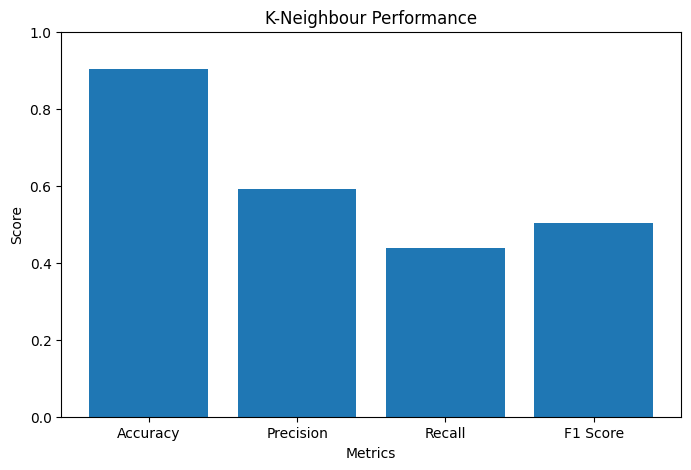

In [155]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(
    y_test,
    y_pred_knn,

)

recall_knn = recall_score(
    y_test,
    y_pred_knn,

)

f1_knn = f1_score(
    y_test,
    y_pred_knn,

)

metrics = [
    accuracy_knn,
    precision_knn,
    recall_knn,
    f1_knn
]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    metric_names,
    metrics
)

plt.ylim(0, 1)

plt.title("K-Neighbour Performance")
plt.xlabel("Metrics")
plt.ylabel("Score")

plt.show()

In [156]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)
print(cm_knn)


[[7028  280]
 [ 521  407]]


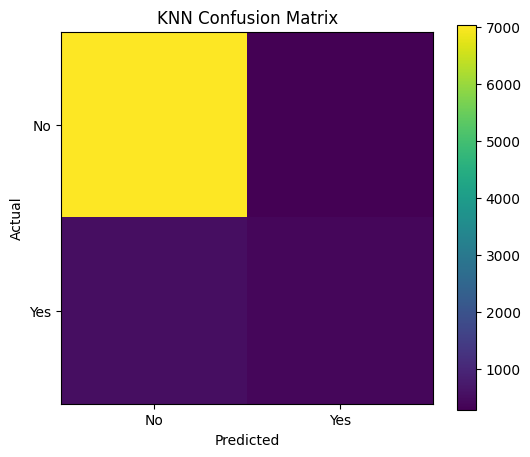

In [157]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(cm_knn)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])

plt.show()

In [158]:
dt = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)

dt.fit(X_train_processed, y_train)


DecisionTreeClassifier(class_weight='balanced', max_depth=8,
                       min_samples_leaf=10, random_state=42)

In [159]:
y_pred_dt = dt.predict(X_test_processed)

In [160]:
y_prob_dt = dt.predict_proba(
    X_test_processed
)[:, 1]

In [161]:
print("Decision Tree Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Precision:",
      precision_score(y_test, y_pred_dt))

print("Recall:",
      recall_score(y_test, y_pred_dt))

print("F1 Score:",
      f1_score(y_test, y_pred_dt))

print("AUC:",
      roc_auc_score(y_test, y_prob_dt))

Decision Tree Results
Accuracy: 0.8502914035939777
Precision: 0.4246169055857637
Recall: 0.9256465517241379
F1 Score: 0.582175533717384
AUC: 0.9341034948709964


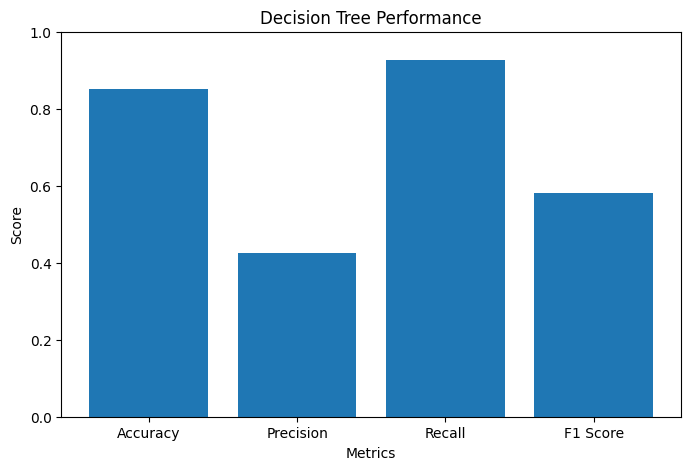

In [162]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,

)

recall_dt = recall_score(
    y_test,
    y_pred_dt,

)

f1_dt = f1_score(
    y_test,
    y_pred_dt,

)

metrics = [
    accuracy_dt,
    precision_dt,
    recall_dt,
    f1_dt
]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    metric_names,
    metrics
)

plt.ylim(0, 1)

plt.title("Decision Tree Performance")
plt.xlabel("Metrics")
plt.ylabel("Score")

plt.show()

In [163]:
lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr.fit(X_train_processed, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [164]:
y_pred_lr = lr.predict(X_test_processed)

In [165]:
y_prob_lr = lr.predict_proba(
    X_test_processed
)[:, 1]

In [166]:
print("Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr))

print("Recall:",
      recall_score(y_test, y_pred_lr))

print("F1 Score:",
      f1_score(y_test, y_pred_lr))

print("AUC:",
      roc_auc_score(y_test, y_prob_lr))

Logistic Regression Results
Accuracy: 0.8627974745021856
Precision: 0.44621938232161873
Recall: 0.9030172413793104
F1 Score: 0.5972915181753385
AUC: 0.9400838181586546


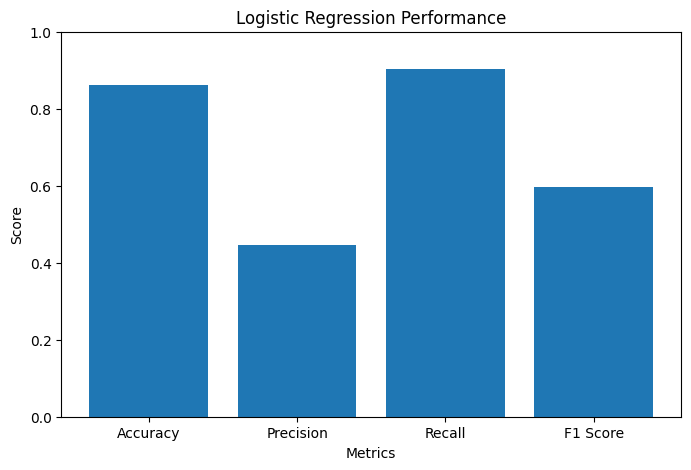

In [167]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test,
    y_pred_lr,

)

recall_lr = recall_score(
    y_test,
    y_pred_lr,

)

f1_lr = f1_score(
    y_test,
    y_pred_lr,

)

metrics = [
    accuracy_lr,
    precision_lr,
    recall_lr,
    f1_lr
]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    metric_names,
    metrics
)

plt.ylim(0, 1)

plt.title("Logistic Regression Performance")
plt.xlabel("Metrics")
plt.ylabel("Score")

plt.show()

In [168]:
nn = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=200,
    early_stopping=True,
    random_state=42
)

In [169]:
nn.fit(
    X_train_processed,
    y_train
)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), random_state=42)

In [170]:
y_pred_nn = nn.predict(
    X_test_processed
)

In [171]:
y_prob_nn = nn.predict_proba(
    X_test_processed
)[:, 1]

In [172]:
print("Neural Network Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred_nn))

print("Precision:",
      precision_score(y_test, y_pred_nn))

print("Recall:",
      recall_score(y_test, y_pred_nn))

print("F1 Score:",
      f1_score(y_test, y_pred_nn))

print("AUC:",
      roc_auc_score(y_test, y_prob_nn))

Neural Network Results
Accuracy: 0.9129431762991743
Precision: 0.6317103620474407
Recall: 0.5452586206896551
F1 Score: 0.5853094274146906
AUC: 0.9457620840647001


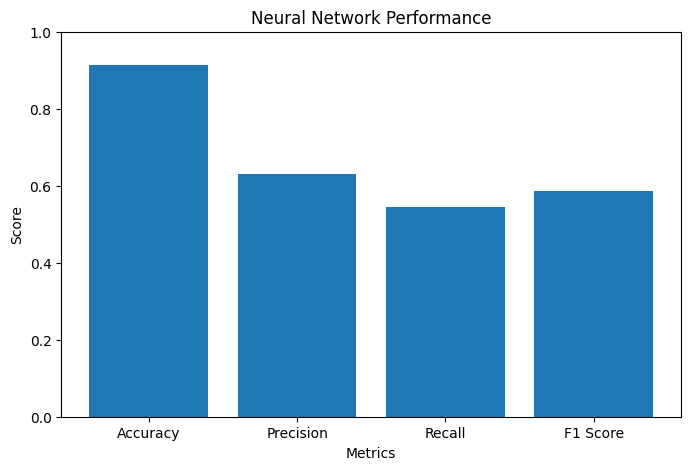

In [173]:
accuracy_nn = accuracy_score(y_test, y_pred_nn)

precision_nn = precision_score(
    y_test,
    y_pred_nn,

)

recall_nn = recall_score(
    y_test,
    y_pred_nn,

)

f1_nn = f1_score(
    y_test,
    y_pred_nn,

)

metrics = [
    accuracy_nn,
    precision_nn,
    recall_nn,
    f1_nn
]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    metric_names,
    metrics
)

plt.ylim(0, 1)

plt.title("Neural Network Performance")
plt.xlabel("Metrics")
plt.ylabel("Score")

plt.show()

In [174]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Decision Tree",
        "Logistic Regression",

        "Neural Network"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_lr),

        accuracy_score(y_test, y_pred_nn)
    ],

    "Precision": [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_lr),

        precision_score(y_test, y_pred_nn)
    ],

    "Recall": [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_lr),

        recall_score(y_test, y_pred_nn)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_lr),

        f1_score(y_test, y_pred_nn)
    ],

    "AUC": [
        roc_auc_score(y_test, y_prob_knn),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_lr),

        roc_auc_score(y_test, y_prob_nn)
    ]
})
print(results)

                 Model  Accuracy  Precision    Recall  F1 Score       AUC
0                  KNN  0.902744   0.592431  0.438578  0.504025  0.871847
1        Decision Tree  0.850291   0.424617  0.925647  0.582176  0.934103
2  Logistic Regression  0.862797   0.446219  0.903017  0.597292  0.940084
3       Neural Network  0.912943   0.631710  0.545259  0.585309  0.945762


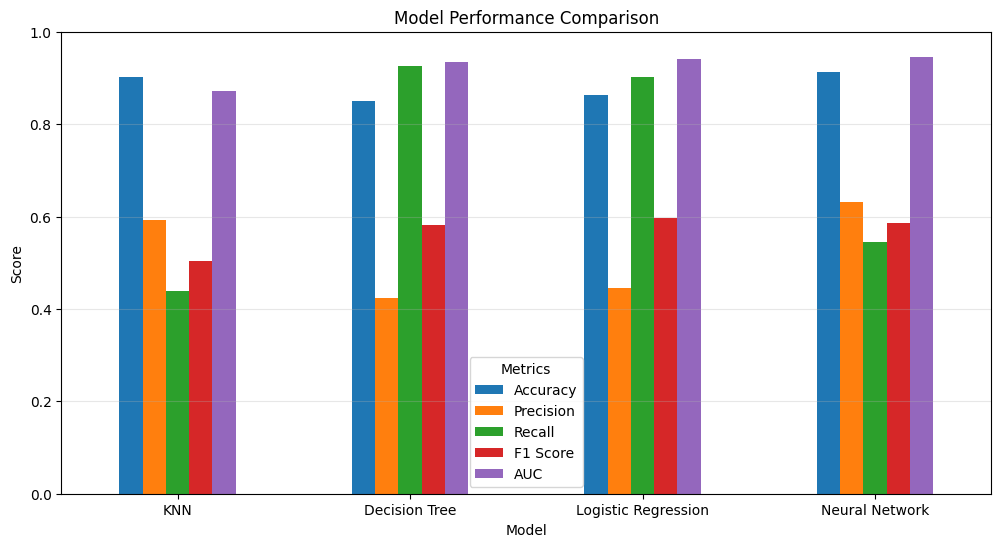

In [175]:
import matplotlib.pyplot as plt

results.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)


plt.show()

In [176]:
from sklearn.cluster import KMeans

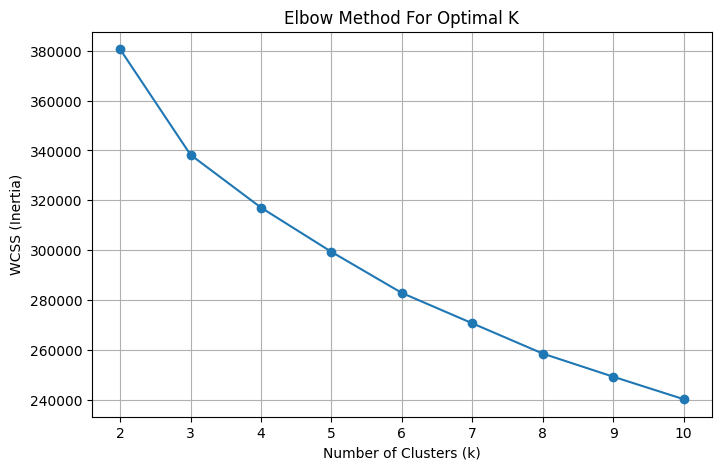

In [177]:
wcss = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    kmeans.fit(X_train_processed)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    wcss,
    marker="o"
)

plt.title("Elbow Method For Optimal K")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.grid(True)

plt.show()

In [178]:
optimal_k = 2

kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans.fit(X_train_processed)

y_pred_kmeans = kmeans.predict(X_test_processed)

In [179]:
acc_original = accuracy_score(y_test, y_pred_kmeans)
acc_flipped = accuracy_score(y_test, 1 - y_pred_kmeans)

if acc_flipped > acc_original:
    y_pred_kmeans = 1 - y_pred_kmeans
else:
    y_pred_kmeans = y_pred_kmeans

In [180]:
print("K-Means Results")

print("Accuracy:",
      accuracy_score(y_test, y_pred_kmeans))

print("Precision:",
      precision_score(y_test, y_pred_kmeans))

print("Recall:",
      recall_score(y_test, y_pred_kmeans))

print("F1 Score:",
      f1_score(y_test, y_pred_kmeans))

print("AUC:",
      roc_auc_score(y_test, y_pred_kmeans))

K-Means Results
Accuracy: 0.7260806216610005
Precision: 0.2527922561429635
Recall: 0.7316810344827587
F1 Score: 0.37576092971776426
AUC: 0.7285252463054187


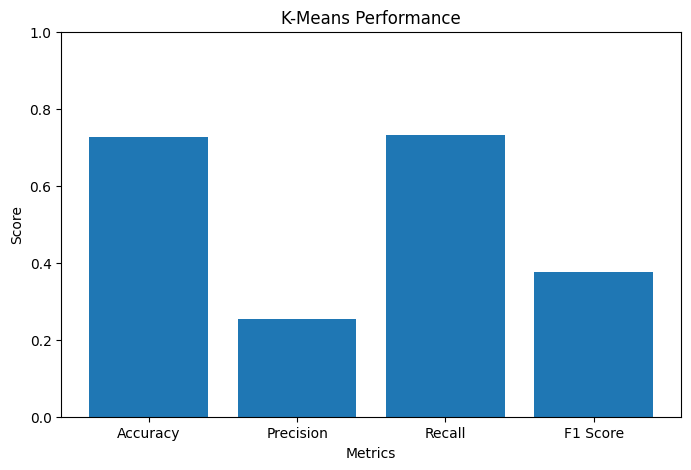

In [181]:
accuracy_kmeans = accuracy_score(y_test, y_pred_kmeans)

precision_kmeans = precision_score(
    y_test,
    y_pred_kmeans
)

recall_kmeans = recall_score(
    y_test,
    y_pred_kmeans
)

f1_kmeans = f1_score(
    y_test,
    y_pred_kmeans
)

metrics = [
    accuracy_kmeans,
    precision_kmeans,
    recall_kmeans,
    f1_kmeans
]

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plt.figure(figsize=(8, 5))

plt.bar(
    metric_names,
    metrics
)

plt.ylim(0, 1)

plt.title("K-Means Performance")
plt.xlabel("Metrics")
plt.ylabel("Score")

plt.show()